# Class 13: Visualization continued, and maps

In class 10 we got as far as reviewing the plots we already knew. This class picks up from there and then moves on to maps.

1. **A plot refresher** — the plots we have made so far, and which question each one answers.
2. **Scatter plots with `plt.scatter`** — coloring and sizing points.
3. **Subplots** — several plots in one figure, in both of matplotlib's two interfaces.
4. **matplotlib as a canvas** — drawing things that are not plots.
5. **Seaborn** — a library built on matplotlib that makes good-looking statistical graphics much easier.
6. **Maps** — geopandas, coordinate reference systems, projections, and choropleth maps.

Parts 1 to 5 are the material homework 5 needs. Maps are not on homework 5.

In [ ]:
import YData

# YData.download.download_class_code(13)   # get class code
# YData.download.download_class_code(13, True)  # get the code with the answers

# Data for the visualization part
YData.download_data("movies.csv")

# Data for the maps part
YData.download_data("dennys.csv")
YData.download_data("States_shapefile.geojson")
YData.download_data("state_demographics.csv")
YData.download_data("ne_110m_graticules_10.prj")
YData.download_data("ne_110m_graticules_10.shp")
YData.download_data("ne_110m_graticules_10.shx")
YData.download_data("ne_110m_graticules_10.dbf")

The file `movies.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `dennys.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `States_shapefile.geojson` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `state_demographics.csv` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `ne_110m_graticules_10.prj` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `ne_110m_graticules_10.shp` already exists.
If you would like a fresh copy, either rename the existing file or call this function again with overwrite=True.
The file `ne_110m_graticules_10.shx` a

'ne_110m_graticules_10.dbf'

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline

## Part 0. Where we were: a plot refresher

Every plot we have made answers a question about a particular *kind* of data. That is the thing worth remembering, more than the function names:

| What you have | What to draw | matplotlib |
|---|---|---|
| one quantitative variable | histogram, box plot | `plt.hist`, `plt.boxplot` |
| one quantitative variable, measured over time | line plot | `plt.plot(x, y)` |
| two quantitative variables | scatter plot | `plt.plot(x, y, ".")`, `plt.scatter(x, y)` |
| one categorical variable | bar chart, pie chart | `plt.bar`, `plt.pie` |
| a quantitative variable split by a categorical one | side-by-side box plots, bar chart of group means | `plt.boxplot([...])`, `plt.bar` |

And whatever you draw, label it: `plt.xlabel`, `plt.ylabel`, `plt.title`, `plt.legend`.

Let's rebuild the Bechdel data from class 10 so we have something to plot.

In [ ]:
# The Bechdel movie data, as in class 10
movies = pd.read_csv("movies.csv")

col_names_to_keep = ['year', 'imdb', 'title', 'clean_test', 'binary', 'budget',
       'domgross', 'budget_2013', 'domgross_2013', 'decade_code', 'imdb_id',
       'rated', 'imdb_rating', 'runtime',  'imdb_votes']

movies = movies[col_names_to_keep]

movies.head()

,year,imdb,title,clean_test,binary,budget,domgross,budget_2013,domgross_2013,decade_code,imdb_id,rated,imdb_rating,runtime,imdb_votes
0,2013,tt1711425,21 &amp; Over,notalk,FAIL,13000000,25682380.0,13000000,25682380.0,1.0,1711425,NaN,NaN,NaN,NaN
1,2012,tt1343727,Dredd 3D,ok,PASS,45000000,13414714.0,45658735,13611086.0,1.0,1343727,NaN,NaN,NaN,NaN
2,2013,tt2024544,12 Years a Slave,notalk,FAIL,20000000,53107035.0,20000000,53107035.0,1.0,2024544,R,8.3,134 min,"143,446"
3,2013,tt1272878,2 Guns,notalk,FAIL,61000000,75612460.0,61000000,75612460.0,1.0,1272878,R,6.8,109 min,"87,301"
4,2013,tt0453562,42,men,FAIL,40000000,95020213.0,40000000,95020213.0,1.0,453562,PG-13,7.6,128 min,"43,608"


### Refresher exercise 1: statistics by group

Re-create the `bechdel_stats` DataFrame from class 10: one row for movies that failed the Bechdel test and one for movies that passed, with columns

- `n`: the number of movies
- `mean_revenue`: mean `domgross_2013`
- `mean_budget`: mean `budget_2013`
- `prop`: the proportion of all movies in that row's group

The first three come from one `groupby().agg()`. `prop` is then a column you compute from `n`.

In [ ]:
bechdel_stats = movies.groupby("binary").agg(n = ("title", "count"),
                                             mean_revenue = ("domgross_2013", "mean"),
                                             mean_budget = ("budget_2013", "mean"))

bechdel_stats["prop"] = bechdel_stats.n/np.sum(bechdel_stats.n)

bechdel_stats

,n,mean_revenue,mean_budget,prop
binary,,,,
FAIL,991,1.077744e+08,6.291156e+07,0.552397
PASS,803,7.959192e+07,4.627417e+07,0.447603


### Refresher exercise 2: one quantitative variable, split by a categorical one

Compare the budgets (in 2013 dollars) of movies that passed and failed the Bechdel test, first with side-by-side box plots and then with overlapping histograms.

For the histograms, two arguments earn their place:

1. `alpha = .5` makes them transparent so you can see both.
2. `density = True` scales each histogram to enclose an area of 1. Use it when the two groups have **different numbers of movies**, as they do here — otherwise the taller histogram is just the bigger group.

Which of the two do you think contrasts the budgets more clearly?

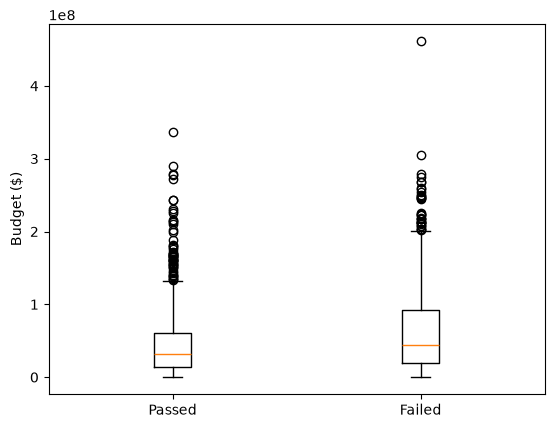

In [ ]:
# Split the movies into two DataFrames
bechdel_passed_df = movies[movies["binary"] == "PASS"]
bechdel_failed_df = movies[movies["binary"] == "FAIL"]

# Side-by-side box plots
plt.boxplot([bechdel_passed_df.budget_2013, bechdel_failed_df.budget_2013],
            tick_labels = ["Passed", "Failed"]);
plt.ylabel("Budget ($)");

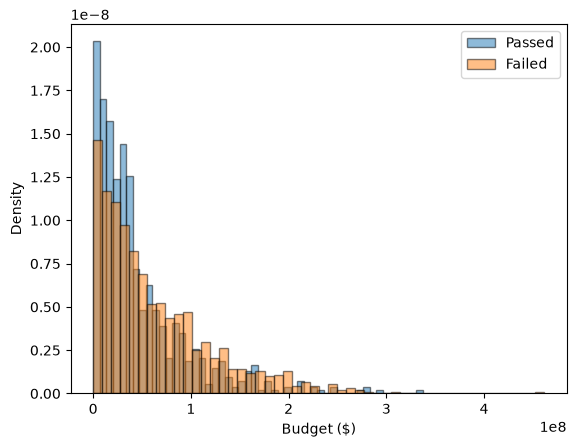

In [ ]:
# Overlapping histograms of the same two groups
plt.hist(bechdel_passed_df.budget_2013, edgecolor = "k", alpha = .5, label = "Passed", bins = 50, density = True);
plt.hist(bechdel_failed_df.budget_2013, edgecolor = "k", alpha = .5, label = "Failed", bins = 50, density = True);
plt.legend();
plt.xlabel("Budget ($)");
plt.ylabel("Density");

### Refresher exercise 3: a time series

Create a DataFrame called `year_revenue` with one row per release `year` and the columns

1. `mean_revenue_2013`: mean revenue in 2013 dollars (`domgross_2013`)
2. `mean_revenue`: mean revenue in the dollars of the day (`domgross`)
3. `n`: the number of movies that year with a recorded revenue

Then plot both revenue columns against the year on one pair of axes, with a legend.

Question to think about: why is the line so choppy before about 1990? Look at `n`.

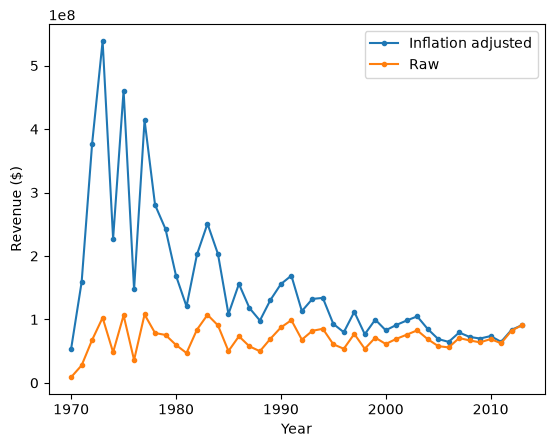

In [ ]:
# Create the year_revenue DataFrame
year_revenue = movies.groupby("year").agg(
    mean_revenue_2013 = ("domgross_2013", "mean"),
    mean_revenue = ("domgross", "mean"),
    n = ("title", "count")
)

# Plot the two time series
plt.plot(year_revenue["mean_revenue_2013"], ".-", label = "Inflation adjusted");
plt.plot(year_revenue["mean_revenue"], ".-", label = "Raw");
plt.legend();
plt.xlabel("Year");
plt.ylabel("Revenue ($)");

The early years are choppy because there are only a handful of movies in each one, so each mean is an average of very few numbers. `year_revenue.n` shows it.

In [ ]:
# How many movies per year?
year_revenue.n.head(10)

year
1970    1
1971    5
1972    3
1973    5
1974    7
1975    5
1976    8
1977    7
1978    8
1979    5
Name: n, dtype: int64

## Part 1. Scatter plots

For a quick scatter plot of two quantitative variables we have been using `plt.plot` with a marker and no line:

```python
plt.plot(x, y, ".");
```

When you want the points themselves to carry more information, use `plt.scatter` instead. It takes arguments that `plt.plot` does not:

- `s`: the size of each point
- `color`: the color of each point
- `marker`: the shape of each point
- `alpha`: transparency, between 0 and 1 — useful when points overlap

Let's start with the simple version.

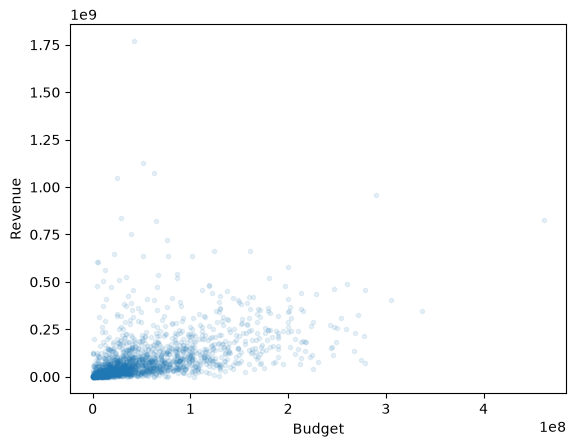

In [ ]:
# Create a basic scatter plot of budget vs. revenue

plt.plot(movies.budget_2013, movies.domgross_2013, ".", alpha = .1);
plt.xlabel("Budget");
plt.ylabel("Revenue");

Let's now create a DataFrame called `movies2` which is the same as our `movies` DataFrame but it also has an additional column called `before2000`. We will use this column to plot points before the year 2000 in a different color than points after 2000. 

In particular, the `before2000` column should be set to the string "red" for movies that occur before 2000 and to the string "blue" for points that occurred after 2000. 

We can then use the `plt.scatter()` function to plot data colored by whether a movie was made before or after 2000.

Do the results show anything interesting/interpretable? 


Remark: red/blue is more colorblind friendly than red/green.

In [ ]:
# Add a column called "before2000" which has values that are
# "red" for years before 2000, "blue" for years after 2000

movies2 = movies.copy()

movies2["before2000"] = "red"
boolean_after_2000 = movies2.year > 2000
movies2.loc[boolean_after_2000, "before2000"] = "blue"

# display first and last row
movies2.iloc[[0, -1]]

,year,imdb,title,clean_test,binary,budget,domgross,budget_2013,domgross_2013,decade_code,imdb_id,rated,imdb_rating,runtime,imdb_votes,before2000
0,2013,tt1711425,21 &amp; Over,notalk,FAIL,13000000,25682380.0,13000000,25682380.0,1.0,1711425,NaN,NaN,NaN,NaN,blue
1793,1970,tt0065466,Beyond the Valley of the Dolls,ok,PASS,1000000,9000000.0,5997631,53978683.0,NaN,65466,X,6.2,109 min,"6,462",red


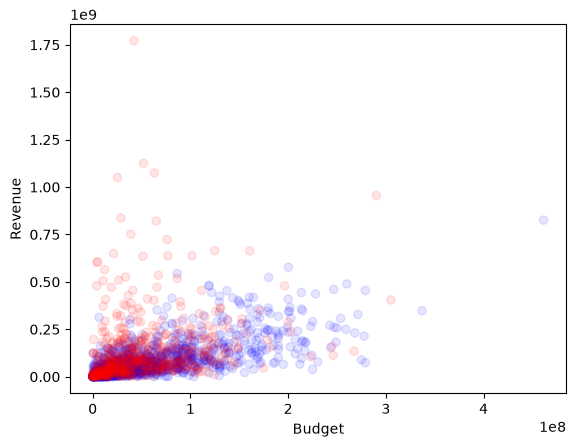

In [ ]:
plt.scatter(movies2.budget_2013, movies2.domgross_2013, 
            color = movies2["before2000"], 
            alpha = .1);

plt.xlabel("Budget");
plt.ylabel("Revenue");

## Part 2. Subplots

Often you want several plots side by side in one figure. matplotlib gives you two ways to do this, and it is worth seeing both because you will meet both in other people's code.

**1. The pyplot interface.** `plt.subplot` says "the figure is a grid this big; from now on I am drawing in this cell of it". Every `plt.`-something afterwards applies to that cell until you call `plt.subplot` again.

```python
plt.subplot(num_rows, num_cols, curr_plot_num);
plt.plot(x, y);
```

The plots are numbered from 1, reading left to right and then top to bottom.

**2. The axes interface.** `plt.subplots` — note the **s** — makes the whole grid at once and hands you back the figure plus an object for each cell. You then draw on a cell by name.

```python
fig, ax = plt.subplots(num_rows, num_cols);
ax[0].plot(x1, y1);
ax[1].plot(x2, y2);
```

Two things to watch with the axes interface:

- `ax` is an **array** of axes, so you must index it: `ax[0]`, `ax[1]`. `ax.plot(...)` on the array itself is an error.
- The labeling methods are named differently: on an axis it is `ax[0].set_ylabel("...")`, not `plt.ylabel("...")`.

Let's draw the same two plots — a bar chart and a pie chart of `prop` — both ways.

,binary,n,mean_revenue,mean_budget,prop
0,FAIL,991,1.077744e+08,6.291156e+07,0.552397
1,PASS,803,7.959192e+07,4.627417e+07,0.447603


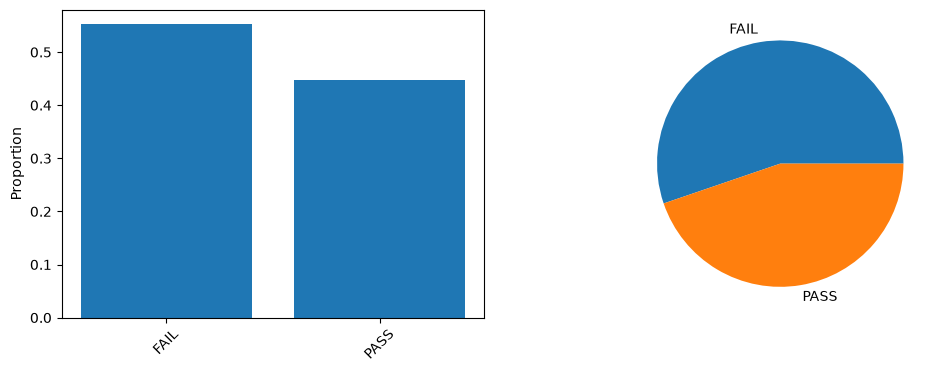

In [ ]:
# reset the index to make "binary" a column in the DataFrame
bechdel_stats2 = bechdel_stats.reset_index()

display(bechdel_stats2)


# change the figure size
plt.figure(figsize = (12, 4));

# subplots
plt.subplot(1, 2, 1);
plt.bar(bechdel_stats2.binary, bechdel_stats2.prop); 
plt.xticks(rotation=45)
plt.ylabel("Proportion");

plt.subplot(1, 2, 2);
plt.pie(bechdel_stats2.prop, labels = bechdel_stats2.binary);

Now the same figure through the axes interface. Notice `plt.subplots` with the **s**, the indexing into `ax`, and `set_ylabel` in place of `ylabel`.

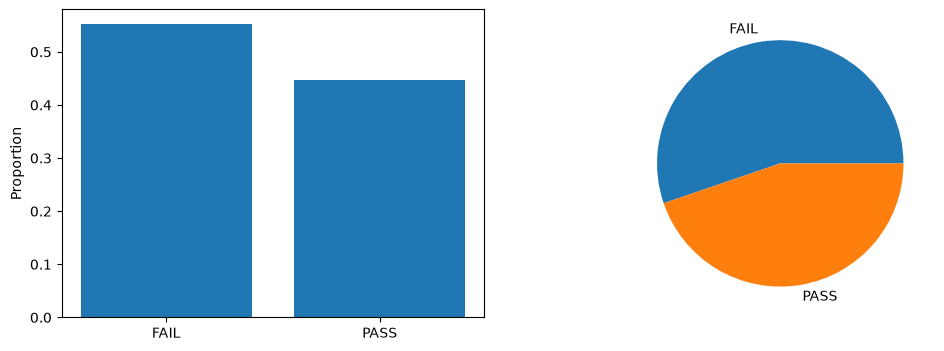

In [ ]:
# using the axes interface

fig, ax = plt.subplots(1, 2);


# set the figure size
fig.set_size_inches(12, 4);
    
# subplots
ax[0].bar(bechdel_stats2.binary, bechdel_stats2.prop); 
ax[0].set_ylabel("Proportion");

ax[1].pie(bechdel_stats2.prop, labels = bechdel_stats2.binary);

Worth saying out loud: `ax` here is a NumPy array of two Axes objects. `ax.set_ylabel(...)` raises `AttributeError` because an array has no such method. Students hit this constantly.

Live demonstration, if you want one: `fig, ax = plt.subplots(1, 2); type(ax)`.

## Part 3. matplotlib as a general canvas

We can use matplotlib as a general canvas to create illustrations as well. For example, in the YData baseball class we drew a baseball diamond and updated where runners were on base.

Let's explore this very briefly...

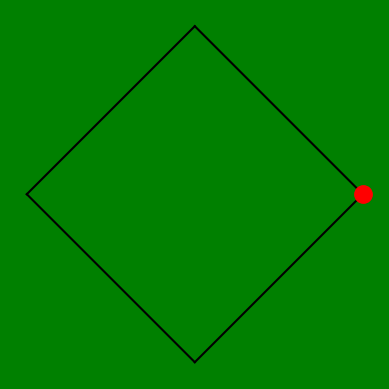

In [ ]:
        
# draw the baseball diamond
plt.plot([0, 1], [0, 1], color = "black");
plt.plot([1, 0], [1, 2], color = "black");
plt.plot([0, -1], [2, 1], color = "black");
plt.plot([-1, 0], [1, 0], color = "black");

# make the axes square
plt.axis("square");

# put a runner on first
plt.plot([1], [1], color = "red", marker=".", markersize=25);

# turn off the axis
plt.axis("off");

# make the field green 
plt.gcf().set_facecolor('green')      # a better hexadecimal green: '#86eb34'

## Part 4. Seaborn

[Seaborn](https://seaborn.pydata.org/index.html) is a Python data visualization library built on top of matplotlib. It produces better-looking plots with less code, and it is built around the idea of handing it a whole DataFrame plus the *names* of the columns you want plotted, rather than handing it arrays.

The first thing it gives you is a theme. `sns.set_theme()` changes the look of **every** plot from then on, including your matplotlib ones.

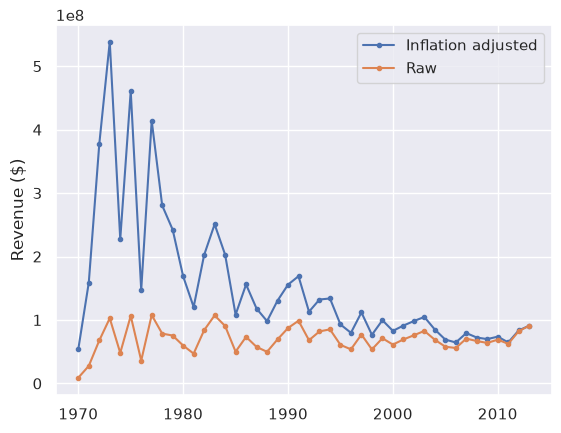

In [ ]:
# Import seaborn
import seaborn as sns

# Apply the default theme
sns.set_theme()   # default style is 'darkgrid')
#sns.set_theme(style='whitegrid')

# Side note: Matplotlib also has themes
# plt.style.available
# plt.style.use('fivethirtyeight')


# Re-draw the revenue line plot, now with the seaborn theme applied
plt.plot(year_revenue["mean_revenue_2013"], ".-", label = "Inflation adjusted");
plt.plot(year_revenue["mean_revenue"], ".-", label = "Raw");
plt.legend();
plt.ylabel("Revenue ($)");

### Figure-level functions

Seaborn has two sorts of plotting function: *axes-level* functions that draw on a single axis, and *figure-level* functions that manage a whole figure for you. We will use the figure-level ones, and there are three, grouped by the kind of data you have:

| What you have | Function |
|---|---|
| two quantitative variables | `sns.relplot()` |
| one quantitative variable | `sns.displot()` |
| a quantitative variable across levels of a categorical one | `sns.catplot()` |

This is the same table as Part 0, with seaborn names in the right-hand column. Each one takes `data = `, then column *names* as strings.

### Two quantitative variables: `sns.relplot()`

Let's plot movie revenue against budget again, this time in seaborn.

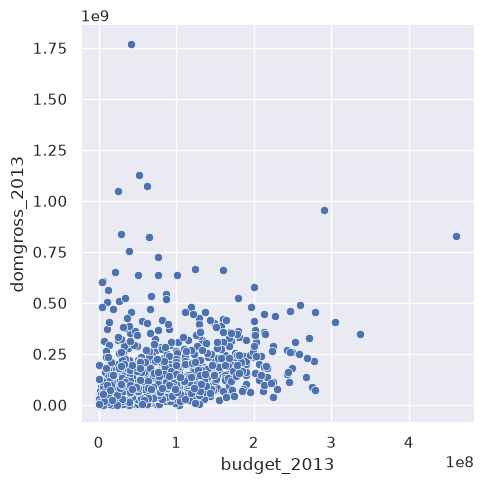

In [ ]:
# plot relationship between budget and revenue (domgross_2013)
sns.relplot(data = movies, x = "budget_2013", y = "domgross_2013");

#### Penguins!

Let's continue to explore the relplot using data on penguins. 

We will also look at mapping other features of our data onto visual properties including: 
- `x`, and `y` column names to be plotted (as we have done before)
- `hue`: The column name to be mapped to the color of the points
- `size`: The column name to be mapped to the size of points
- `style`: The column name to be mapped to the style of the markers
- `col`: the column name to be mapped to faceting to compare multiple subplots

In [ ]:
# Let's look at some penguins
penguins = sns.load_dataset("penguins")

print(type(penguins))

penguins.head()

<class 'pandas.DataFrame'>


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


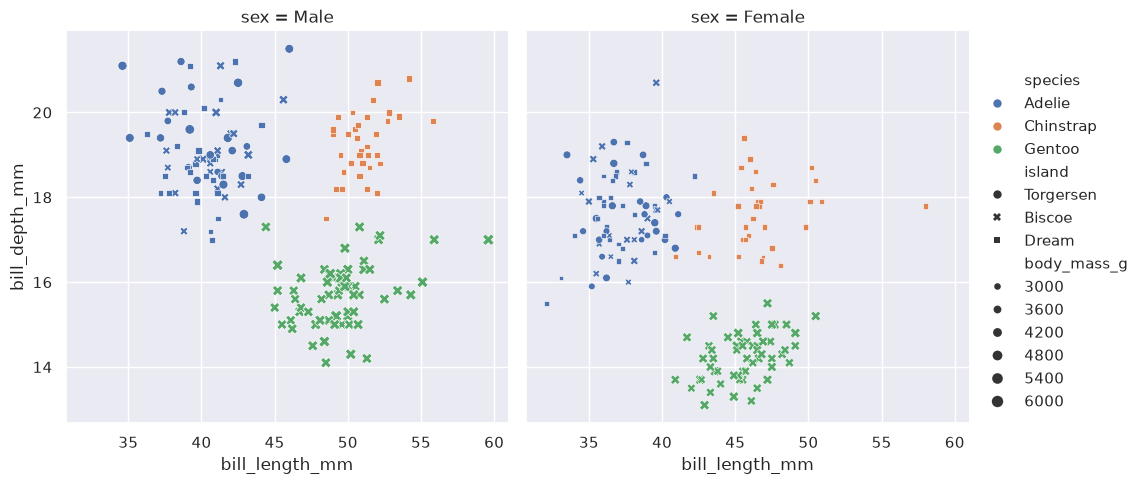

In [ ]:
# plotting bill size on x, and y axes and other properties
sns.relplot(data = penguins, 
            x = "bill_length_mm", 
            y = "bill_depth_mm",
            hue = "species",
            size = "body_mass_g",
            style = "island",
            col = "sex");

### Plotting a single quantitative variable using sns.displot()

We can plot a single quantitative variables using the `sns.displot()` function.

Properties we can set include
- `x`: The name of the data column you want to plot
- `hue`: The name of the column that gives each group its own color
- `kind` The type of plot

Different options for `kind` are: “hist”, “kde”, “ecdf”


#### Warm-up exercise

Please create a `sns.displot()` to create a visualization of *flipper length*, where each *species* is in a different color (i.e., different hue). Also, experiment with the "kind" of visualization and choose the kind you think creates the best visualization. 

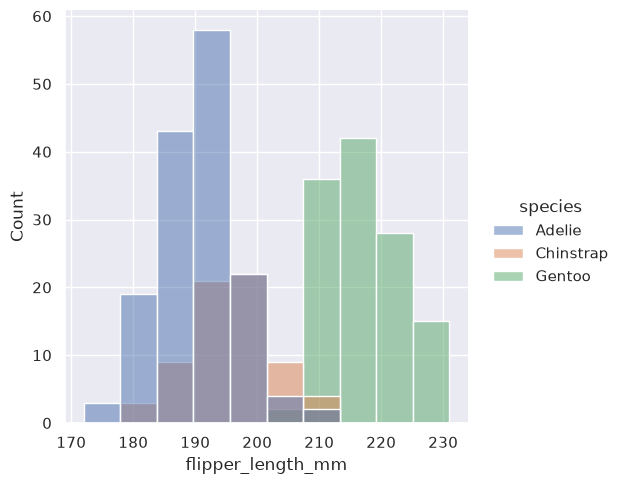

In [ ]:
# plot the flipper length
sns.displot(data = penguins, 
            x="flipper_length_mm", 
            hue="species", 
            kind="hist");  # Experiment with "hist", "kde" and "ecdf"

### Plotting a quantitative variable for different categorical variable levels

We can plot a quantitative variable for different categorical variable levels using the `sns.catplot()` function.

We specify: 
- `x`: categorical x-value column name
- `y`: Quantitative y-value column name
- `kind`: The type of plot

The `kind` argument can be set to the following: “strip”, “swarm”, “box”, “violin”, “boxen”, “point”, “bar”, or “count”

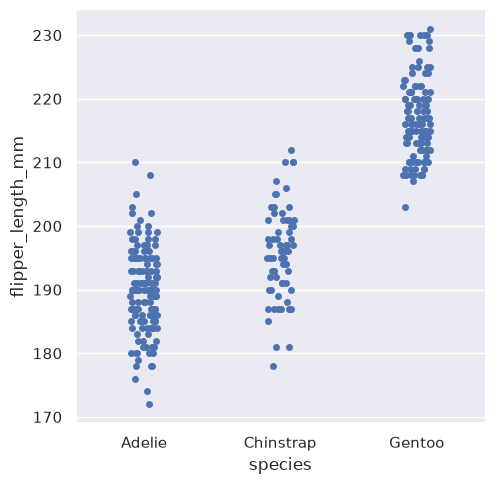

In [ ]:
# plot flipper length for the different species using different kinds of plots
sns.catplot(data = penguins, 
            x = "species", 
            y = "flipper_length_mm", 
            kind = "strip");

# also try “strip”, “swarm”, “box”, “violin”, “boxen”, “point”, or “bar”

### Pairs plots

One of the most useful visualizations for exploring the relationships between several quantitative variables is to create a "pairs plot" which creates a series of scatter plots between all quantitative variables in the data.  We can do this in seaborn using the `sns.pairplot(data)` function!


Use the `pairplot()` function to visualize the relationships between all columns in the `penguins` DataFrame. Also, make each species have a different color. 

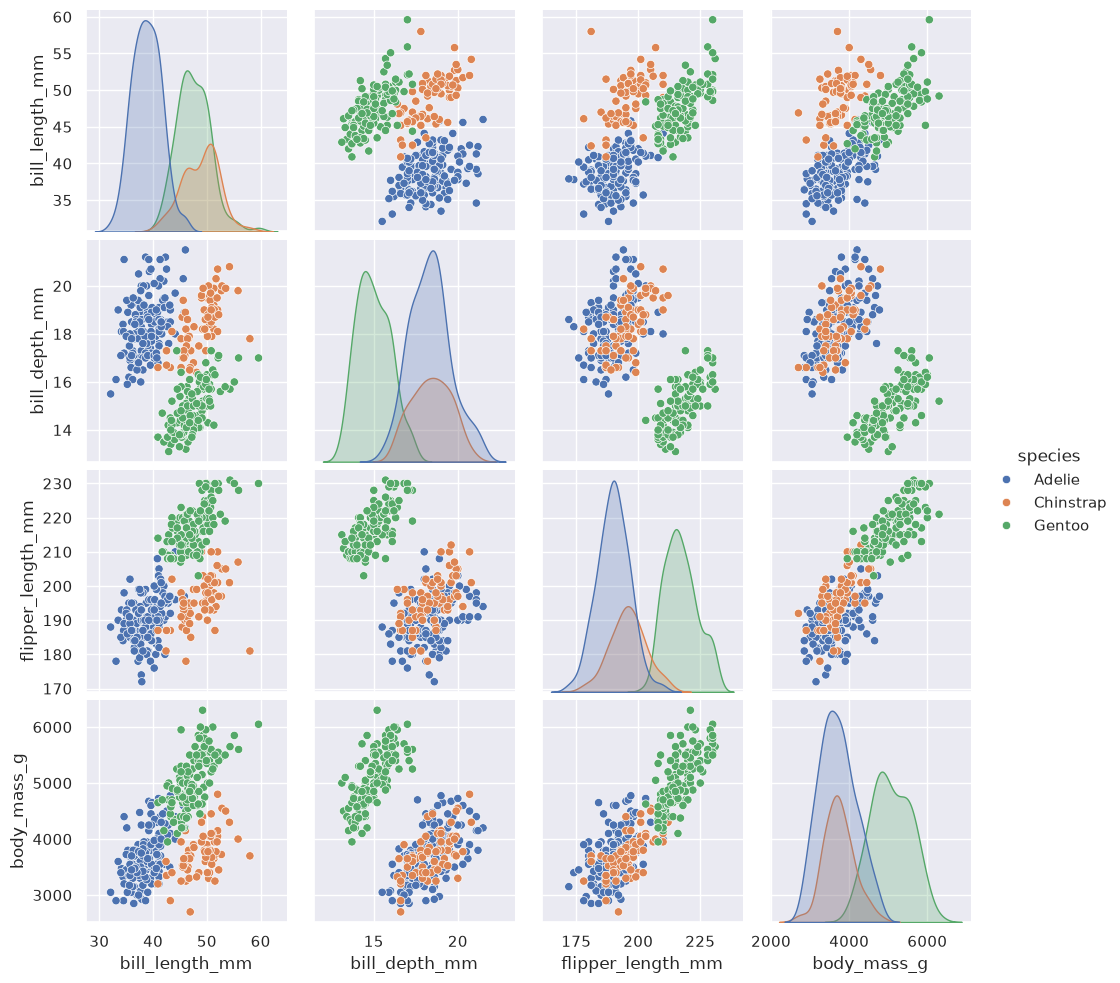

In [ ]:
# Create pair plots for the different variables in the penguins data set

sns.pairplot(penguins, hue = "species");

A note for homework 5: question 2.4 asks for subplots (Part 2 above) and the whole of section 3 is seaborn (Part 4). Everything homework 5 needs has now been covered.

<img src = "https://i.imgflip.com/1ezfdq.jpg">

## Part 5. Maps

Everything from here on is the maps class. It is not needed for homework 5.

### Spatial mapping with geopandas

Visualizing spatial data through maps is another powerful way to see trends in data. There are several mapping packages in Python. Here we will use the geopandas package to create maps. 

The geopandas package defines a geopandas DataFrame, which is the same as a pandas DataFrame but has an additional column called `geometry` which specifies geographic information. 

Let's explore this now!

### Visualizing boundaries

Let's start by looking at some geopandas DataFrames and visualizing some geometric boundaries.

In [ ]:
import geopandas as gpd

# see which maps come with geopandas
gpd.datasets.available
# Oh no! They don't provide datasets anymore!

[]

Let's get a geopandas DataFrame that has the countries in the world...

In [ ]:
# View the world geopandas DataFrame
# read data into a geodataframe
# NOTE: this downloads ~215 KB from naciscdn.org when the cell runs.
# Once ne_110m_admin_0_countries.zip is in the course data repo, replace
# these two lines with:  world = gpd.read_file("ne_110m_admin_0_countries.zip")
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url)
# In previous versions of geopandas, the dataset was included with the package
#world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# print the data type
print(type(world))

# look at the first few rows of the data
world.head()

ERROR 1: PROJ: proj_create_from_database: Open of /tmp/envs/geo3/share/proj failed


<class 'geopandas.geodataframe.GeoDataFrame'>


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


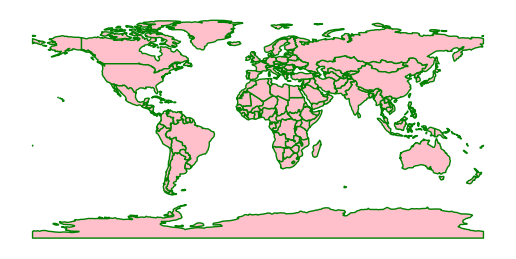

In [ ]:
# Plot a world map with particular properties

ax = world.plot(color = "pink", edgecolor = "green");

ax.set_axis_off();

In [ ]:
world.query("ADMIN == 'United States of America'")

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


In [ ]:
world.query("SOVEREIGNT == 'United States of America'")

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
45,Admin-0 country,1,5,United States of America,US1,1,2,Dependency,1,Puerto Rico,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-66.28243 18.51476, -65.7713 18.4266..."


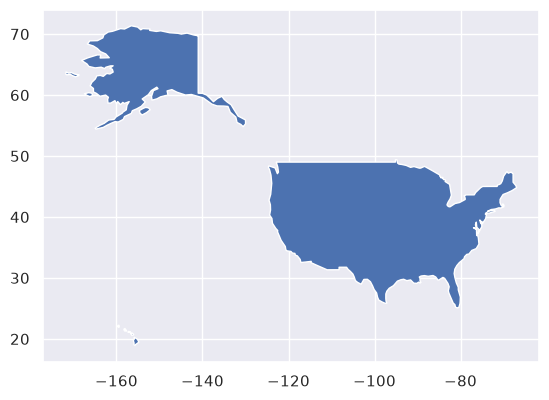

In [ ]:
# Plot just the United States

world.query("ADMIN == 'United States of America'").plot();

### Coordinate reference systems and projections

A coordinate reference system (CRS) is a framework used to precisely measure locations on the surface of the Earth as coordinates. The goal of any spatial reference system is to create a common reference frame in which locations can be measured precisely and consistently as coordinates, which can then be shared unambiguously, so that any recipient can identify the same location that was originally intended by the originator.

There are two different types of coordinate reference systems: Geographic Coordinate Systems and Projected Coordinate Systems. [Projected coordinate systems](https://en.wikipedia.org/wiki/List_of_map_projections) map 3D coordinates into a 2D plane so they can be plotted. Different projected coordinate systems preserve different properties, such as keeping all angles intact which is useful for navigation (e.g., the Mercator projection) or keeping the size of land areas intact (e.g., the Eckert IV projection). 

A detailed discussion of CRS is beyond the scope of the class. But for the purposes of this class, it is just important that all layers in a map are using the same project (otherwise, for example, data points representing cities and the underlying spatial map won't line up). 

Let's very briefly explore different map projections... 

In [ ]:
# Read Graticules (lines on a map)
graticules = gpd.read_file("ne_110m_graticules_10.shp")
print(graticules.crs)
graticules.head(3)

EPSG:4326


,degrees,direction,display,dd,ScaleRank,geometry
0,80,N,80 N,80.0,6,"LINESTRING (180 79.99848, 179.99664 79.99848, ..."
1,70,N,70 N,70.0,6,"LINESTRING (180 69.99847, 179.99664 69.99847, ..."
2,60,N,60 N,60.0,6,"LINESTRING (180 59.99866, 179.99664 59.99866, ..."


EPSG:4326


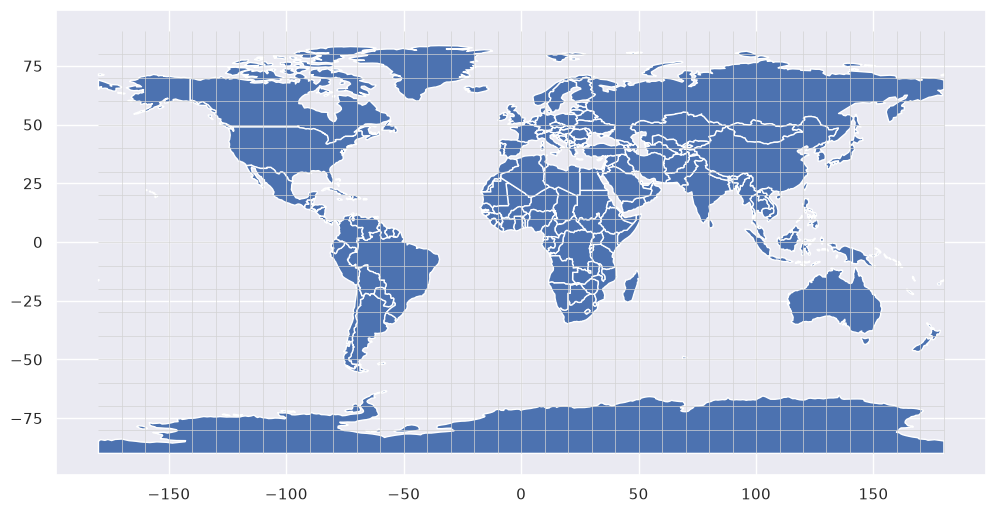

In [ ]:
# Web Mercator projection - preserves angles (EPSG:4326 projection)

print(world.crs) # print the default CRS


# plot the map
fig, ax = plt.subplots(figsize=(12,10))
world.plot(ax = ax);
graticules.plot(ax=ax, color="lightgray", linewidth=0.5);

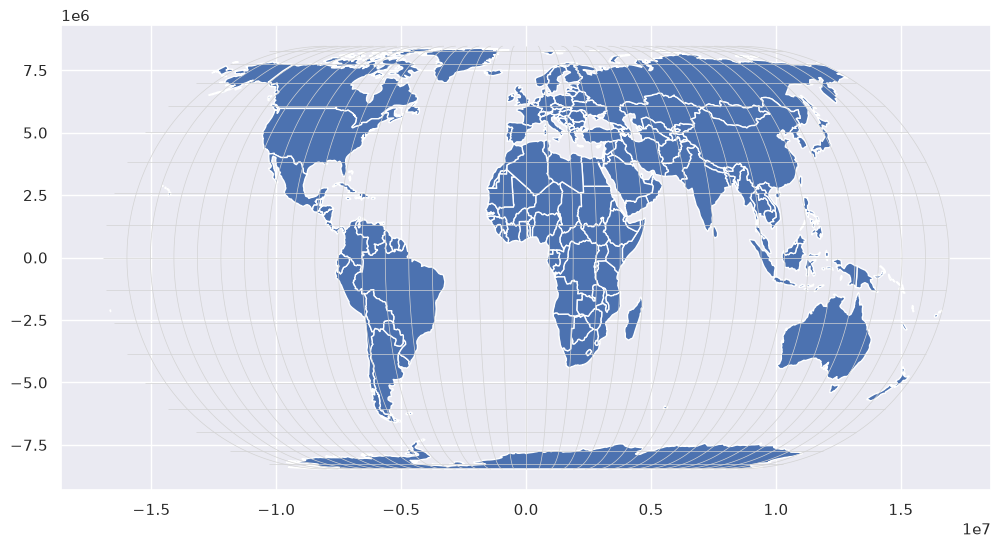

In [ ]:
# Eckert IV is an equal-area projection  ("ESRI:54012")

fig, ax = plt.subplots(figsize=(12,10))
world.to_crs("ESRI:54012").plot(ax = ax);
graticules.to_crs("ESRI:54012").plot(ax=ax, color="lightgray", linewidth=0.5);

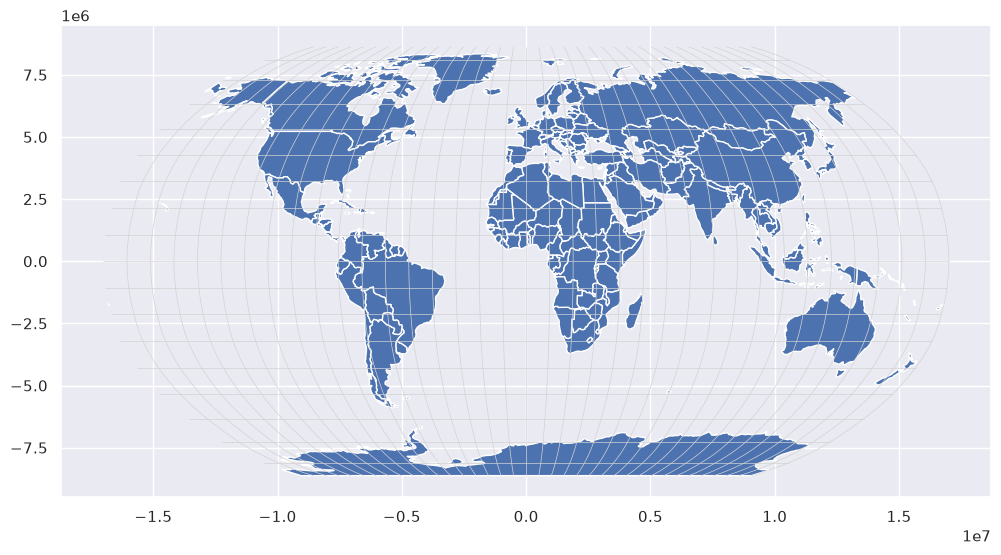

In [ ]:
# Robinson projection - neither equal-area nor conformal ("ESRI:54030") 

fig, ax = plt.subplots(figsize=(12,10))
world.to_crs("ESRI:54030").plot(ax = ax);
graticules.to_crs("ESRI:54030").plot(ax=ax, color="lightgray", linewidth=0.5);

To learn more about "What your favorite map projection says about you" see: https://xkcd.com/977/

### Maps with layers and markers

We can also plot points on a map. When doing so, it's important that the points and the underlying map use the same coordinate reference system (CRS).

Let's add Denny's locations to the map of the United States!

In [ ]:
# Let's start by getting a map of just the United States

state_map = world.query("ADMIN == 'United States of America'")

state_map

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


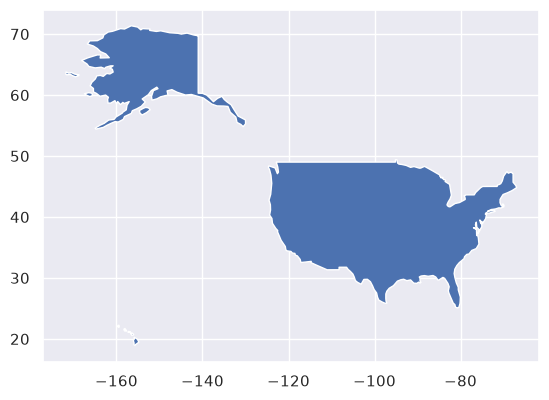

In [ ]:
# visualize just the United States

state_map.plot();

In [ ]:
# Get the coordinate reference system (CRS) for our map

print(state_map.crs)

EPSG:4326


Let's now load our Denny's data!

In [ ]:
# Let's load our Denny's data
dennys = pd.read_csv("dennys.csv")
dennys.head(3)

,Unnamed: 0,address,city,state,zip,longitude,latitude
0,1,2900 Denali,Anchorage,AK,99503,-149.8767,61.1953
1,2,3850 Debarr Road,Anchorage,AK,99508,-149.8090,61.2097
2,3,1929 Airport Way,Fairbanks,AK,99701,-147.7600,64.8366


To convert longitude and latitude coordinates into geometric objects; i.e., we will convert them into Shaply objects.  We can use the `gpd.points_from_xy(long, lat)` function. 

In [ ]:
# Let's convert our longitude and latitude coordinates into geometric (Shapely) objects 

dennys_geometries = gpd.points_from_xy(dennys["longitude"], dennys["latitude"])
dennys_geometries[0:5]

<GeometryArray>
[<POINT (-149.877 61.195)>,  <POINT (-149.809 61.21)>,
  <POINT (-147.76 64.837)>,  <POINT (-85.468 32.603)>,
  <POINT (-86.832 33.562)>]
Length: 5, dtype: geometry

In [ ]:
# Let's now convert out data into a geopandas DataFrame

dennys_gpd = gpd.GeoDataFrame(dennys, geometry=dennys_geometries)
dennys_gpd.head(3)

,Unnamed: 0,address,city,state,zip,longitude,latitude,geometry
0,1,2900 Denali,Anchorage,AK,99503,-149.8767,61.1953,POINT (-149.8767 61.1953)
1,2,3850 Debarr Road,Anchorage,AK,99508,-149.8090,61.2097,POINT (-149.809 61.2097)
2,3,1929 Airport Way,Fairbanks,AK,99701,-147.7600,64.8366,POINT (-147.76 64.8366)


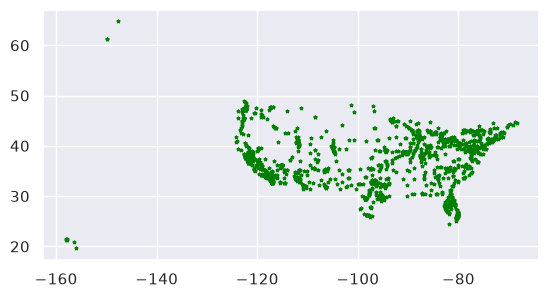

In [ ]:
# We can plot the location of the Denny's using the plot function

dennys_gpd.plot(marker='*', color='green', markersize=5);

In [ ]:
# Let's check the CRS

print(dennys_gpd.crs)

None


Before plotting data, we should set the appropriate coordinate reference system (CRS). This is particularly important when we are combining different layers on a map, such as putting city locations on the map that has the outlines of regional borders. 

The CRS that uses longitude and latitude coordinates is the [World Geodetic System 1984 (WGS84)](https://epsg.io/4326). This system is often referred to by its EPSG Geodetic Parameter Dataset code which is `4326`. 

Thus, we should set the set coordinate system to be EPSG 4326. We can do this using the method `.set_crs(4326)`. Let's set this on our `dennys_gpd` DataFrame. 

In [ ]:
# Let's set the CRS to match the CRS of our map (which is EPSG 4326)

dennys_gpd = dennys_gpd.set_crs(4326)

print(dennys_gpd.crs)

dennys_gpd.head(3)

EPSG:4326


,Unnamed: 0,address,city,state,zip,longitude,latitude,geometry
0,1,2900 Denali,Anchorage,AK,99503,-149.8767,61.1953,POINT (-149.8767 61.1953)
1,2,3850 Debarr Road,Anchorage,AK,99508,-149.8090,61.2097,POINT (-149.809 61.2097)
2,3,1929 Airport Way,Fairbanks,AK,99701,-147.7600,64.8366,POINT (-147.76 64.8366)


Now that we have our Denny's location in the same coordinate system as our map, we can add the points to the map. 

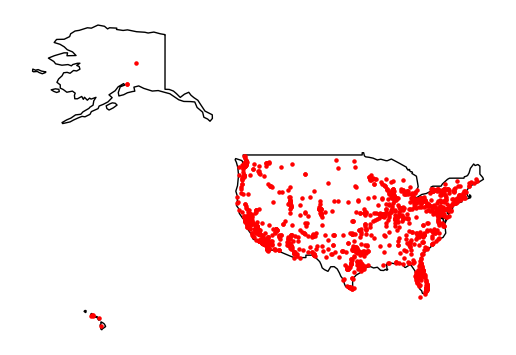

In [ ]:
#state_map = gpd.read_file("States_shapefile.geojson")

base = state_map.plot(color='white', edgecolor='black')

ax = dennys_gpd.plot(ax=base, color='red', markersize=5);

ax.set_axis_off();

### Choropleth maps

In choropleth maps, predefined regions are filled in with colors based on values of interest. 

Typically to create a choropleth map we join data of interest onto a map. 

Let's explore this now...

In [ ]:
import plotly.express as px

gapminder_2007 = px.data.gapminder().query("year == 2007")   # We only want plotly for its copy of the gapminder data: unlike our own
# gapminder_data.csv it carries the iso_alpha and iso_num country codes,
# which we need further down to join onto the map reliably.

gapminder_2007.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12
47,Angola,Africa,2007,42.731,12420476,4797.231267,AGO,24
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


In [ ]:
# Join the gapminder data onto our world map

world2 = world.merge(gapminder_2007, left_on = "ADMIN", right_on = "country")

world2.head(3)

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_UA,geometry,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,NaN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",Canada,Americas,2007,80.653,33390141,36319.235010,CAN,124
1,Admin-0 country,1,2,Indonesia,IDN,0,2,Sovereign country,1,Indonesia,...,NaN,"MULTIPOLYGON (((141.00021 -2.60015, 141.01706 ...",Indonesia,Asia,2007,70.650,223547000,3540.651564,IDN,360
2,Admin-0 country,1,2,Argentina,ARG,0,2,Sovereign country,1,Argentina,...,NaN,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5...",Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


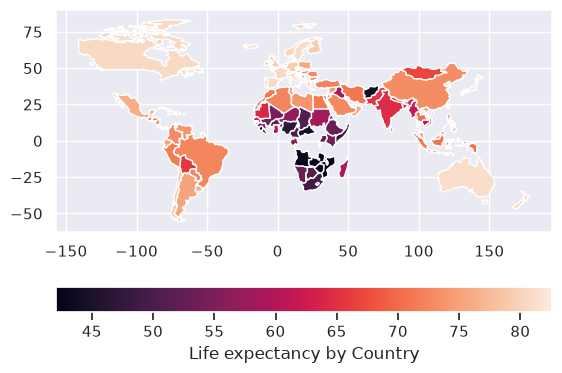

In [ ]:
# Plot a choropleth map of life expectancy

world2.plot(column='lifeExp', legend = True,
           legend_kwds={'label': "Life expectancy by Country",
                        'orientation': "horizontal"});

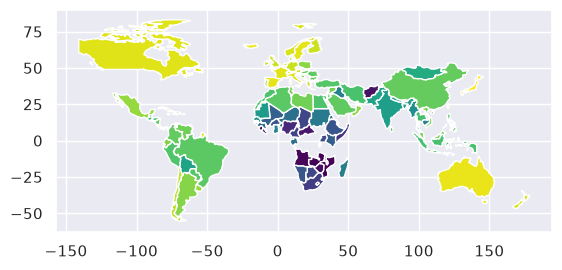

In [ ]:
# Change the color scale

world2.plot(column='lifeExp', cmap='viridis');  #cmap='OrRd'

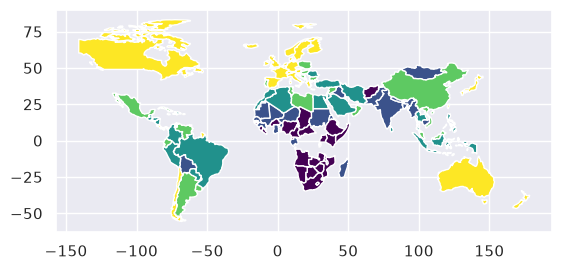

In [ ]:
# We can plot quantiles

#world2.plot(column='lifeExp', cmap='OrRd', scheme='quantiles');

world2.plot(column='lifeExp', cmap='viridis', scheme='quantiles');

#### BUT WAIT! Are we missing some countries??? Let's try to find out why.

New commands we'll try here are not for the exam.

In [ ]:
# Wait! are some countries missing???
# Let's look for Sudan and South Sudan.
display(gapminder_2007[gapminder_2007["country"].str.startswith("S")])
display(world[world["ADMIN"].str.startswith("S")])

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
1307,Sao Tome and Principe,Africa,2007,65.528,199579,1598.435089,STP,678
1319,Saudi Arabia,Asia,2007,72.777,27601038,21654.831940,SAU,682
1331,Senegal,Africa,2007,63.062,12267493,1712.472136,SEN,686
1343,Serbia,Europe,2007,74.002,10150265,9786.534714,SRB,688
1355,Sierra Leone,Africa,2007,42.568,6144562,862.540756,SLE,694
1367,Singapore,Asia,2007,79.972,4553009,47143.179640,SGP,702
1379,Slovak Republic,Europe,2007,74.663,5447502,18678.314350,SVK,703
1391,Slovenia,Europe,2007,77.926,2009245,25768.257590,SVN,705
1403,Somalia,Africa,2007,48.159,9118773,926.141068,SOM,706
1415,South Africa,Africa,2007,49.339,43997828,9269.657808,ZAF,710


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
12,Admin-0 country,1,6,Somalia,SOM,0,2,Sovereign country,1,Somalia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((41.58513 -1.68325, 40.993 -0.85829, ..."
14,Admin-0 country,1,3,Sudan,SDN,0,2,Sovereign country,1,Sudan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((24.56737 8.22919, 23.80581 8.66632, ..."
25,Admin-0 country,1,2,South Africa,ZAF,0,2,Sovereign country,1,South Africa,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((16.34498 -28.57671, 16.82402 -28.082..."
42,Admin-0 country,1,4,Suriname,SUR,0,2,Sovereign country,1,Suriname,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-54.52475 2.31185, -55.09759 2.52375..."
51,Admin-0 country,1,3,Senegal,SEN,0,2,Sovereign country,1,Senegal,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-16.71373 13.59496, -17.12611 14.373..."
64,Admin-0 country,1,4,Sierra Leone,SLE,0,2,Sovereign country,1,Sierra Leone,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-13.24655 8.90305, -12.71196 9.34271..."
96,Admin-0 country,1,2,South Korea,KOR,0,2,Sovereign country,1,South Korea,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((126.17476 37.74969, 126.23734 37.840..."
108,Admin-0 country,1,3,Syria,SYR,0,2,Sovereign country,1,Syria,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((35.71992 32.70919, 35.7008 32.71601,..."
110,Admin-0 country,1,3,Sweden,SWE,0,2,Sovereign country,1,Sweden,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((11.02737 58.85615, 11.46827 59.43239..."
127,Admin-0 country,1,4,Switzerland,CHE,0,2,Sovereign country,1,Switzerland,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((9.59423 47.52506, 9.63293 47.3476, 9..."


In [ ]:
# Which entries didn't make it?
world[~world["ADMIN"].isin(world2["ADMIN"])]

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
0,Admin-0 country,1,6,Fiji,FJI,0,2,Sovereign country,1,Fiji,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Admin-0 country,1,7,Western Sahara,SAH,0,2,Indeterminate,1,Western Sahara,...,Unrecognized,Unrecognized,Unrecognized,NaN,NaN,Unrecognized,NaN,NaN,NaN,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
5,Admin-0 country,1,3,Kazakhstan,KA1,1,1,Sovereignty,1,Kazakhstan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((87.35997 49.21498, 86.59878 48.54918..."
6,Admin-0 country,1,3,Uzbekistan,UZB,0,2,Sovereign country,1,Uzbekistan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((55.96819 41.30864, 55.92892 44.99586..."
7,Admin-0 country,1,2,Papua New Guinea,PNG,0,2,Sovereign country,1,Papua New Guinea,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((141.00021 -2.60015, 142.73525 ..."
11,Admin-0 country,1,2,Democratic Republic of the Congo,COD,0,2,Sovereign country,1,Democratic Republic of the Congo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((29.34 -4.49998, 29.51999 -5.41998, 2..."
18,Admin-0 country,1,2,Russia,RUS,0,2,Sovereign country,1,Russia,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((178.7253 71.0988, 180 71.51571..."
19,Admin-0 country,1,4,The Bahamas,BHS,0,2,Sovereign country,1,The Bahamas,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-78.98 26.79, -78.51 26.87, -7..."


In [ ]:
#Let's look for the US
display(gapminder_2007[gapminder_2007["country"].str.startswith("U")])
display(world[world["ADMIN"].str.startswith("U")])

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
1595,Uganda,Africa,2007,51.542,29170398,1056.380121,UGA,800
1607,United Kingdom,Europe,2007,79.425,60776238,33203.261280,GBR,826
1619,United States,Americas,2007,78.242,301139947,42951.653090,USA,840
1631,Uruguay,Americas,2007,76.384,3447496,10611.462990,URY,858


,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
1,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
6,Admin-0 country,1,3,Uzbekistan,UZB,0,2,Sovereign country,1,Uzbekistan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((55.96819 41.30864, 55.92892 44.99586..."
28,Admin-0 country,1,4,Uruguay,URY,0,2,Sovereign country,1,Uruguay,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-57.62513 -30.21629, -56.97603 -30.1..."
84,Admin-0 country,1,4,United Arab Emirates,ARE,0,2,Sovereign country,1,United Arab Emirates,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((51.57952 24.2455, 51.75744 24.29407,..."
112,Admin-0 country,1,3,Ukraine,UKR,0,2,Sovereign country,1,Ukraine,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((31.78599 52.10168, 32.15944 52.06125..."
143,Admin-0 country,1,2,United Kingdom,GB1,1,2,Country,1,United Kingdom,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-6.19788 53.86757, -6.95373 54..."
168,Admin-0 country,1,3,Uganda,UGA,0,2,Sovereign country,1,Uganda,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((33.90371 -0.95, 31.86617 -1.02736, 3..."


In [ ]:
# What is that SOVEREIGNT thing?
display(world[world["SOVEREIGNT"].str.startswith("United States")])

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
4,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."
45,Admin-0 country,1,5,United States of America,US1,1,2,Dependency,1,Puerto Rico,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((-66.28243 18.51476, -65.7713 18.4266..."


In [ ]:
# Codes to be more standard. 
# Would this work better?
world3 = world.merge(gapminder_2007, left_on = "SOV_A3", right_on = "iso_alpha")
world3

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_UA,geometry,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,NaN,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...",Tanzania,Africa,2007,52.517,38139640,1107.482182,TZA,834
1,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,NaN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",Canada,Americas,2007,80.653,33390141,36319.235010,CAN,124
2,Admin-0 country,1,2,Indonesia,IDN,0,2,Sovereign country,1,Indonesia,...,NaN,"MULTIPOLYGON (((141.00021 -2.60015, 141.01706 ...",Indonesia,Asia,2007,70.650,223547000,3540.651564,IDN,360
3,Admin-0 country,1,2,Argentina,ARG,0,2,Sovereign country,1,Argentina,...,NaN,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5...",Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32
4,Admin-0 country,1,2,Chile,CHL,0,2,Sovereign country,1,Chile,...,NaN,"MULTIPOLYGON (((-68.63401 -52.63637, -68.63335...",Chile,Americas,2007,78.553,16284741,13171.638850,CHL,152
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117,Admin-0 country,1,3,Rwanda,RWA,0,2,Sovereign country,1,Rwanda,...,NaN,"POLYGON ((30.4191 -1.13466, 30.81613 -1.69891,...",Rwanda,Africa,2007,46.242,8860588,863.088464,RWA,646
118,Admin-0 country,1,5,Bosnia and Herzegovina,BIH,0,2,Sovereign country,1,Bosnia and Herzegovina,...,NaN,"POLYGON ((18.56 42.65, 17.67492 43.02856, 17.2...",Bosnia and Herzegovina,Europe,2007,74.852,4552198,7446.298803,BIH,70
119,Admin-0 country,1,5,Republic of Serbia,SRB,0,2,Sovereign country,1,Republic of Serbia,...,NaN,"POLYGON ((18.82982 45.90887, 18.82984 45.90888...",Serbia,Europe,2007,74.002,10150265,9786.534714,SRB,688
120,Admin-0 country,1,6,Montenegro,MNE,0,2,Sovereign country,1,Montenegro,...,NaN,"POLYGON ((20.0707 42.58863, 19.80161 42.50009,...",Montenegro,Europe,2007,74.543,684736,9253.896111,MNE,499


In [ ]:
# Here, the numerial code works a little better
world4 = world.copy()
# ISO_N3 is stored as text in the shapefile; iso_num is a number in the
# gapminder data, so one side has to be converted before they can match.
world4["ISO_N3_NUM"] = world["ISO_N3"].astype("int64")
world5 = world4.merge(gapminder_2007, left_on = "ISO_N3_NUM", right_on = "iso_num", how="inner")
world5

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,geometry,ISO_N3_NUM,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Admin-0 country,1,3,United Republic of Tanzania,TZA,0,2,Sovereign country,1,United Republic of Tanzania,...,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3...",834,Tanzania,Africa,2007,52.517,38139640,1107.482182,TZA,834
1,Admin-0 country,1,2,Canada,CAN,0,2,Sovereign country,1,Canada,...,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025...",124,Canada,Americas,2007,80.653,33390141,36319.235010,CAN,124
2,Admin-0 country,1,2,United States of America,US1,1,2,Country,1,United States of America,...,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312...",840,United States,Americas,2007,78.242,301139947,42951.653090,USA,840
3,Admin-0 country,1,2,Indonesia,IDN,0,2,Sovereign country,1,Indonesia,...,"MULTIPOLYGON (((141.00021 -2.60015, 141.01706 ...",360,Indonesia,Asia,2007,70.650,223547000,3540.651564,IDN,360
4,Admin-0 country,1,2,Argentina,ARG,0,2,Sovereign country,1,Argentina,...,"MULTIPOLYGON (((-68.63401 -52.63637, -68.25 -5...",32,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,Admin-0 country,1,3,Rwanda,RWA,0,2,Sovereign country,1,Rwanda,...,"POLYGON ((30.4191 -1.13466, 30.81613 -1.69891,...",646,Rwanda,Africa,2007,46.242,8860588,863.088464,RWA,646
128,Admin-0 country,1,5,Bosnia and Herzegovina,BIH,0,2,Sovereign country,1,Bosnia and Herzegovina,...,"POLYGON ((18.56 42.65, 17.67492 43.02856, 17.2...",70,Bosnia and Herzegovina,Europe,2007,74.852,4552198,7446.298803,BIH,70
129,Admin-0 country,1,5,Republic of Serbia,SRB,0,2,Sovereign country,1,Republic of Serbia,...,"POLYGON ((18.82982 45.90887, 18.82984 45.90888...",688,Serbia,Europe,2007,74.002,10150265,9786.534714,SRB,688
130,Admin-0 country,1,6,Montenegro,MNE,0,2,Sovereign country,1,Montenegro,...,"POLYGON ((20.0707 42.58863, 19.80161 42.50009,...",499,Montenegro,Europe,2007,74.543,684736,9253.896111,MNE,499


How many countries did each join keep? And does the map change once we join on the numeric code instead of the name?

joining on country name:   122 countries
joining on numeric code:   132 countries


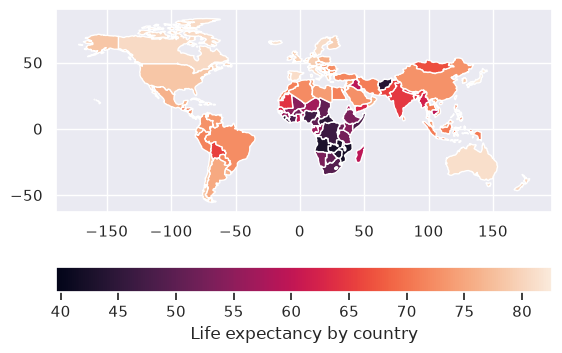

In [ ]:
print("joining on country name:  ", world2.shape[0], "countries")
print("joining on numeric code:  ", world5.shape[0], "countries")

# Re-draw the choropleth with the repaired join
world5.plot(column='lifeExp', legend = True,
            legend_kwds={'label': "Life expectancy by country",
                         'orientation': "horizontal"});

In [ ]:
world2 = world5

### Another choropleth map example

Let's fit a choropleth map examining which states in the USA are growing in terms of people having lots of children. 

Any thoughts on which state this might be? 

To start, let's load a map with the outlines of the states in the USA, and load demographic data.

In [ ]:
state_map = gpd.read_file("States_shapefile.geojson")

print(state_map.crs)

state_map.head(3)

EPSG:4326


,FID,Program,State_Code,State_Name,Flowing_St,FID_1,geometry
0,1,PERMIT TRACKING,AL,ALABAMA,F,919,"POLYGON ((-85.07007 31.9807, -85.11515 31.9074..."
1,2,,AK,ALASKA,N,920,"MULTIPOLYGON (((-161.33379 58.73325, -161.3824..."
2,3,AZURITE,AZ,ARIZONA,F,921,"POLYGON ((-114.52063 33.02771, -114.55909 33.0..."


In [ ]:
# load demographic data on the states

state_demographics = pd.read_csv("state_demographics.csv")
state_demographics.head(3)

,State,under_5,over_64,bachelors_degree,total
0,Alabama,295811.997,741954.681,1095959.202,4849377
1,Alaska,54518.168,69252.808,202601.300,736732
2,Arizona,430814.976,1070305.956,1810769.196,6731484


In [ ]:
# In order to join the DataFrames, we need to make sure the states have the same capitalization

state_demographics2 = state_demographics.copy()
state_demographics2["State"] = state_demographics["State"].apply(str.upper)

state_demographics2.head()

,State,under_5,over_64,bachelors_degree,total
0,ALABAMA,295811.997,741954.681,1.095959e+06,4849377
1,ALASKA,54518.168,69252.808,2.026013e+05,736732
2,ARIZONA,430814.976,1070305.956,1.810769e+06,6731484
3,ARKANSAS,192813.985,465719.933,5.962402e+05,2966369
4,CALIFORNIA,2522162.500,5005522.500,1.191237e+07,38802500


In [ ]:
# Join the demographic information on to the the USA map

state_map_demo = state_map.merge(state_demographics2, 
                                 left_on = "State_Name", right_on = "State")
state_map_demo.head(3)

,FID,Program,State_Code,State_Name,Flowing_St,FID_1,geometry,State,under_5,over_64,bachelors_degree,total
0,1,PERMIT TRACKING,AL,ALABAMA,F,919,"POLYGON ((-85.07007 31.9807, -85.11515 31.9074...",ALABAMA,295811.997,741954.681,1095959.202,4849377
1,2,,AK,ALASKA,N,920,"MULTIPOLYGON (((-161.33379 58.73325, -161.3824...",ALASKA,54518.168,69252.808,202601.300,736732
2,3,AZURITE,AZ,ARIZONA,F,921,"POLYGON ((-114.52063 33.02771, -114.55909 33.0...",ARIZONA,430814.976,1070305.956,1810769.196,6731484


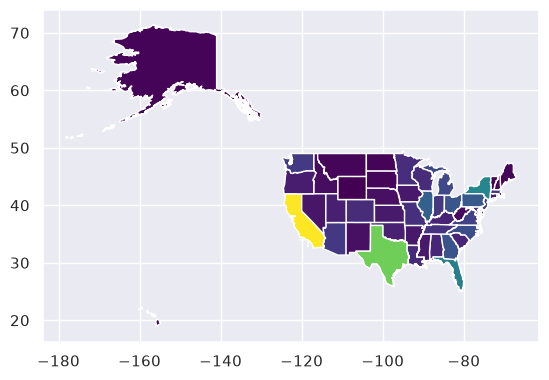

In [ ]:
# Let's plot the map 

state_map_demo.plot(column = "under_5", cmap='viridis');

Is there anything [wrong with this map](https://xkcd.com/1138/)? 

In [ ]:
# Let's look at the proportion of people under the age of 5

state_map_demo2 = state_map_demo.copy()

state_map_demo2["percent_under_5"] = 100 * state_map_demo["under_5"]/state_map_demo["total"]

state_map_demo2.head(3)

,FID,Program,State_Code,State_Name,Flowing_St,FID_1,geometry,State,under_5,over_64,bachelors_degree,total,percent_under_5
0,1,PERMIT TRACKING,AL,ALABAMA,F,919,"POLYGON ((-85.07007 31.9807, -85.11515 31.9074...",ALABAMA,295811.997,741954.681,1095959.202,4849377,6.1
1,2,,AK,ALASKA,N,920,"MULTIPOLYGON (((-161.33379 58.73325, -161.3824...",ALASKA,54518.168,69252.808,202601.300,736732,7.4
2,3,AZURITE,AZ,ARIZONA,F,921,"POLYGON ((-114.52063 33.02771, -114.55909 33.0...",ARIZONA,430814.976,1070305.956,1810769.196,6731484,6.4


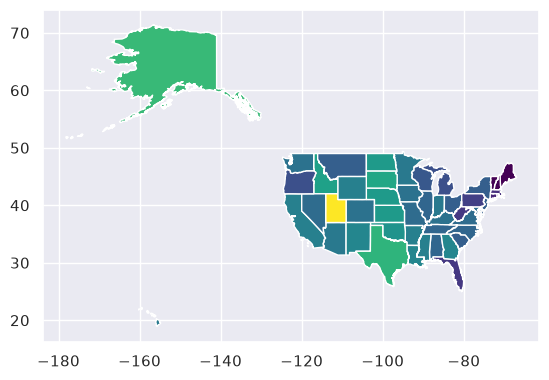

In [ ]:
# Let's plot the new map

state_map_demo2.plot(column = "percent_under_5", cmap='viridis');

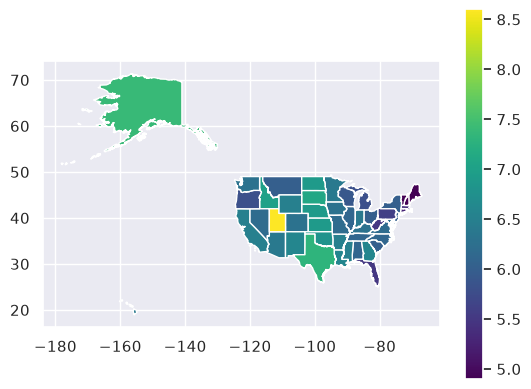

In [ ]:
# But what does it mean?
state_map_demo2.plot(column = "percent_under_5", cmap='viridis',legend=True);